# PWM と V/F 変換

アナログの電圧を、**時間**で表すデジタルの信号に変える回路です。**PWM**(パルス幅変調)は、一定の周期のパルスの**幅**(High の時間の割合、デューティ比)で電圧を表します。モーターや LED の明るさの制御、D 級アンプで使われます。**V/F 変換**は、パルスの**周波数**で電圧を表します。パルスを数えれば A/D 変換になり、離れた場所へ雑音に強い形で送れます。

この回では、入力とデューティ比、PWM を平均して元の電圧に戻す(D/A 変換)、三角波とのこぎり波の搬送波の違い、入力と周波数(V/F)を見ます。

## 回路

![PWM 変調器](05_pwm_vf/circuit.svg)

比較器(5-1)で、入力と三角波(搬送波)をくらべます。入力が三角波より高いあいだ High になるので、入力が高いほど High の時間が長くなります。V/F 変換器は、6-2 の VCO の方形波を出力にしたものです(LM331 などの IC がある)。

## 原理

**PWM**:搬送波の振幅を $A$ とすると、デューティ比 $D$ は入力に比例します。

$$D = \frac{1}{2} + \frac{V_\mathrm{in} - V_\mathrm{ref}}{2A} \qquad (0 \le D \le 1)$$

High が $V_\mathrm{DD}$、Low が 0 V なので、出力の**平均**は $V_\mathrm{DD} \times D$ です。PWM をローパスフィルタ(2-1)に通すと、入力に比例した電圧に戻ります(D/A 変換)。搬送波が三角波なら、パルスの両側の縁が動きます。のこぎり波なら、片側の縁は動かず、もう片側だけが動きます。

**V/F 変換**:出力は 50 % の方形波で、周波数が入力に比例します。

$$f = f_0 + k\,(V_\mathrm{in} - V_\mathrm{ref})$$

一定の時間(ゲート時間)のあいだパルスを数えると、その時間の入力の平均がわかります。雑音が平均されるので、ゆっくりした高い精度の A/D 変換になります。

![PWM と V/F(模式図)](05_pwm_vf/response.svg)

## Mimic の設定と回路定数

| Mimic(Python) | ライブラリ(Arduino) | 回路 |
|---|---|---|
| `lab.mimic.pwm(fc, a, wave)` | `mimic.setPwmModulator(fc, a, MIMIC_OSC_WAVE_TRIANGLE)` など | 搬送波の周波数 $f_c$(Hz)と振幅 $A$(V)、波形 `"triangle"` か `"sawtooth"` |
| `lab.mimic.vf(k, f0)` | `mimic.setVfConverter(k, f0)` | 感度 $k$(Hz/V)、Vref での周波数 $f_0$(Hz、省略で 0) |

- どちらも出力はデジタル(0 V と VDD)です(5-1 の比較器と同じ)。
- パルスの縁は Mimic の 5 µs のサンプルにそろうので、PWM のデューティ比のきざみは $f_c$ / 200 kHz(1 kHz で 0.5 %)です。V/F の 1 周期は ±5 µs ゆらぎますが、平均の周波数は正確です。
- V/F は、周波数が 0 Hz になると High のまま止まります。

## 準備:測定器につなぐ

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from mimiclab import MimicLab, measure

lab = MimicLab()  # finds the Arduino; or MimicLab("COM5")
lab

MimicLab(port='COM4', ver=0.1.4, mimic=20261125)

In [2]:
def show(t, ch1, ch2, label, extra=None):
    fig, ax = plt.subplots(figsize=(9, 3.5))
    ax.plot(t * 1e3, ch2, lw=0.8, color="C1", label=f"CH2: output ({label})")
    ax.plot(t * 1e3, ch1, color="C0", label="CH1: input")
    if extra is not None:
        ax.plot(t * 1e3, extra[1], color="C3", lw=2, label=extra[0])
    ax.set_xlabel("Time [ms]")
    ax.set_ylabel("Voltage [V]")
    ax.grid(True)
    ax.legend(loc="upper right")
    plt.show()


def duty(v):
    # Part of the time the digital output is HIGH
    return np.mean(v > 2.5)


def moving_average(v, n):
    # The average of the last n points (a simple low-pass filter)
    return np.convolve(v, np.ones(n) / n, mode="same")

## 実験 1:入力とデューティ比

搬送波を 200 Hz、振幅 1 V の三角波にして、入力の直流を 1.5〜3.5 V まで変えます。デューティ比は 0 % から 100 % まで直線で変わるはずです。それぞれの入力で取り込んだ波形の最初の 20 ms(4 周期)を並べてから、入力とデューティ比のグラフにします。

input 1.501 V: duty   0.1 % (theory   0.0 %)
input 2.000 V: duty  25.1 % (theory  25.0 %)
input 2.501 V: duty  50.1 % (theory  50.0 %)
input 3.001 V: duty  75.3 % (theory  75.1 %)
input 3.501 V: duty 100.0 % (theory 100.0 %)


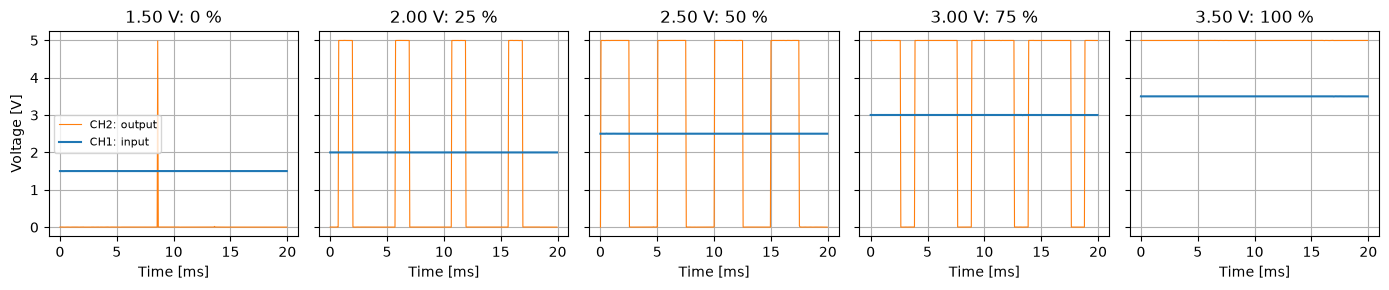

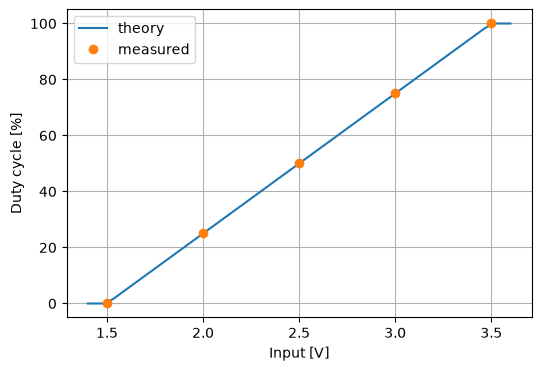

In [3]:
inputs = (1.5, 2.0, 2.5, 3.0, 3.5)

lab.mimic.pwm(200, 1.0)
vin, d = [], []
fig, axes = plt.subplots(1, len(inputs), figsize=(14, 3), sharey=True)
for ax, v in zip(axes, inputs):
    lab.fg.dc(v)
    time.sleep(0.1)
    t, ch1, ch2 = lab.scope.capture(2000)   # 0.1 s = 20 periods
    vin.append(ch1.mean())
    d.append(duty(ch2))
    theory = min(max(0.5 + (vin[-1] - 2.5) / 2, 0), 1)
    print(f"input {vin[-1]:.3f} V: duty {d[-1] * 100:5.1f} % (theory {theory * 100:5.1f} %)")
    n = t < 0.02
    ax.plot(t[n] * 1e3, ch2[n], color="C1", lw=0.8, label="CH2: output")
    ax.plot(t[n] * 1e3, ch1[n], color="C0", label="CH1: input")
    ax.set_title(f"{vin[-1]:.2f} V: {d[-1] * 100:.0f} %")
    ax.set_xlabel("Time [ms]")
    ax.grid(True)
axes[0].set_ylabel("Voltage [V]")
axes[0].legend(loc="center left", fontsize=8)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6, 4))
v_th = np.linspace(1.4, 3.6, 50)
ax.plot(v_th, np.clip(0.5 + (v_th - 2.5) / 2, 0, 1) * 100, "-", label="theory")
ax.plot(vin, np.array(d) * 100, "o", label="measured")
ax.set_xlabel("Input [V]")
ax.set_ylabel("Duty cycle [%]")
ax.grid(True)
ax.legend()
plt.show()

デューティ比は、0.1 秒に取り込んだ点のうち High の点の割合から求めています。測定器の取り込み(50 µs ごと)のぶん、1 % 程度ばらつきます。

## 実験 2:PWM を平均して元に戻す(D/A 変換)

入力に 5 Hz、振幅 0.8 V の正弦波を入れ、500 Hz の PWM にします。出力を搬送波の 1 周期(2 ms)ずつ平均すると、$V_\mathrm{DD} \times D$ = 2.5 + 2.5 × (入力 − 2.5)、つまり入力を Vref のまわりで 2.5 倍にした正弦波に戻るはずです。

average vs 2.5 + 2.5 (input - 2.5): difference 98 mV rms (the ripple, and the 0.1 ms steps of the capture)


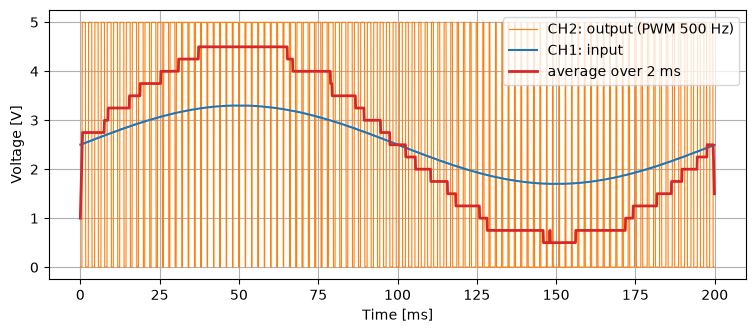

In [4]:
lab.fg.sine(5, 0.8)
lab.mimic.pwm(500, 1.0)
time.sleep(0.2)
t, ch1, ch2 = lab.scope.capture(2000, fs=10000)   # 0.2 s
avg = moving_average(ch2, 20)                     # 20 points = 2 ms = one carrier period
expected = 2.5 + 2.5 * (ch1 - 2.5)
inner = slice(20, -20)                            # the ends of the average are incomplete
print(f"average vs 2.5 + 2.5 (input - 2.5): difference {np.std((avg - expected)[inner]) * 1e3:.0f} mV rms "
      "(the ripple, and the 0.1 ms steps of the capture)")
show(t, ch1, ch2, "PWM 500 Hz", ("average over 2 ms", avg))

平均した線(赤)は、入力と同じ形の正弦波で、Vref のまわりで 2.5 倍(= VDD /(2A))になっています。PWM は「1 か 0」しか出さないのに、平均すると途中の電圧を表せます。マイコンの `analogWrite()`(PWM)で LED の明るさを変えられるのも、目が明るさを平均しているからです。平均の線に残る小さなぎざぎざは、平均の時間が短い(1 周期だけ)ための**リプル**です。

## 実験 3:V/F 変換

感度 1000 Hz/V、$f_0$ = 0 にして、入力の直流を 2.4〜3.5 V まで変えながら周波数を測ります。周波数は 1000 × (入力 − 2.5)、つまり 0〜1000 Hz になるはずです(2.4 V では 0 Hz で止まる)。波形の最初の 10 ms を並べてから、入力と周波数のグラフにします。

input 2.401 V:     0.0 Hz (theory     0.0 Hz)
input 2.601 V:   103.1 Hz (theory   100.9 Hz)
input 2.801 V:   303.3 Hz (theory   301.0 Hz)
input 3.001 V:   504.0 Hz (theory   501.4 Hz)
input 3.500 V:  1005.1 Hz (theory  1000.4 Hz)


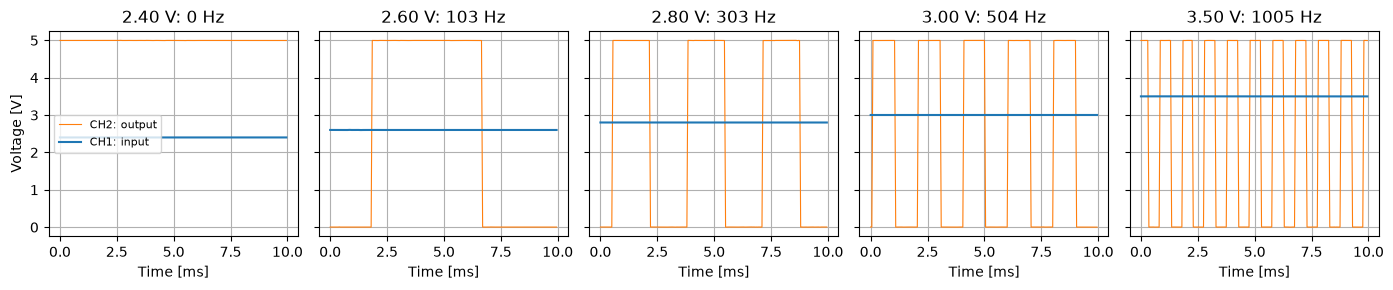

sensitivity from the measurement: 1003 Hz/V (setting 1000 Hz/V)


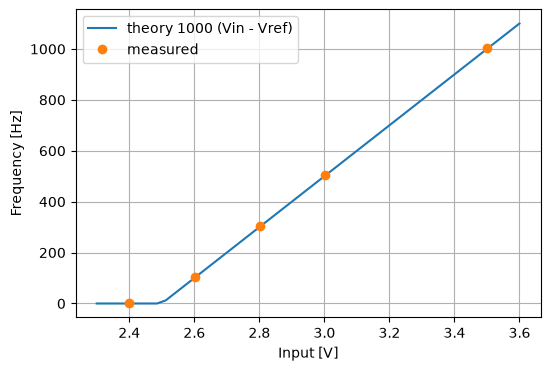

In [5]:
inputs = (2.4, 2.6, 2.8, 3.0, 3.5)

lab.mimic.vf(1000)
vin, freq = [], []
fig, axes = plt.subplots(1, len(inputs), figsize=(14, 3), sharey=True)
for ax, v in zip(axes, inputs):
    lab.fg.dc(v)
    time.sleep(0.1)
    t, ch1, ch2 = lab.scope.capture(2000)
    f = measure(t, ch2)[1]
    vin.append(ch1.mean())
    freq.append(0.0 if f is None else f)   # no edges: stopped (0 Hz)
    print(f"input {vin[-1]:.3f} V: {freq[-1]:7.1f} Hz (theory {max(1000 * (vin[-1] - 2.5), 0):7.1f} Hz)")
    n = t < 0.01
    ax.plot(t[n] * 1e3, ch2[n], color="C1", lw=0.8, label="CH2: output")
    ax.plot(t[n] * 1e3, ch1[n], color="C0", label="CH1: input")
    ax.set_title(f"{vin[-1]:.2f} V: {freq[-1]:.0f} Hz")
    ax.set_xlabel("Time [ms]")
    ax.grid(True)
axes[0].set_ylabel("Voltage [V]")
axes[0].legend(loc="center left", fontsize=8)
plt.tight_layout()
plt.show()

vin, freq = np.array(vin), np.array(freq)
run = freq > 0
print(f"sensitivity from the measurement: {np.polyfit(vin[run], freq[run], 1)[0]:.0f} Hz/V (setting 1000 Hz/V)")
fig, ax = plt.subplots(figsize=(6, 4))
v_th = np.linspace(2.3, 3.6, 50)
ax.plot(v_th, np.clip(1000 * (v_th - 2.5), 0, None), "-", label="theory 1000 (Vin - Vref)")
ax.plot(vin, freq, "o", label="measured")
ax.set_xlabel("Input [V]")
ax.set_ylabel("Frequency [Hz]")
ax.grid(True)
ax.legend()
plt.show()

周波数は入力に比例し、Vref(2.5 V)以下では 0 Hz になって出力は High のまま止まります。測った周波数は、理論より数 Hz 高く出ることがあります。Mimic の Vref と測定器の目盛りの数 mV のずれに感度(1000 Hz/V)を掛けたぶんと、Mimic と Arduino の時計の違い(6-1、0.1 % 程度)のためです。センサーの 0 が 0 V のときは、`vref(0)` にすると、0 V で 0 Hz になります。

**VCO(6-2)との違い**:周波数の決め方は同じです。違うのは、使い道に合わせた出力です。VCO はアナログの波形(正弦波など)を出し、音や搬送波などの「信号」として使います。V/F は 0 V と VDD のデジタルの方形波を出し、マイコンのカウンタで数えたり、光や長い線で離れた場所に送ったりする「測定値の運び手」として使います。縁が鋭いので、数えまちがいが起きにくくなっています。また、V/F は Vref(入力の 0)で 0 Hz から始めるのが基本です。

## やってみよう

下のセルの値(大文字の名前)を**1 つずつ**変えて実行し、オシロの波形と数値がどう変わるかを自分の目で確かめましょう。どの値を順に試すとよいかと、何が見えるはずかは「ヒント」に書いてあります。

> Run All で最後まで実行したあと(接続を閉じたあと)にやるときは、最初の「測定器につなぐ」のセルをもう一度実行してから始めます。

### 1. 三角波とのこぎり波の搬送波
<details><summary>ヒント</summary>

`WAVE` を `"sawtooth"` → `"triangle"` と変えて、パルスの縁のどちらが動くかを見ましょう。入力はゆっくりした正弦波で、20 ms(搬送波 4 周期)を拡大しています。

- のこぎり波:立ち下がりの縁の位置は動かず、立ち上がりの縁だけが動きます。
- 三角波:パルスの中心の位置が動かず、両側の縁が同じだけ動きます。モーターの制御では、こちらの方が高調波が少なくなります。

</details>

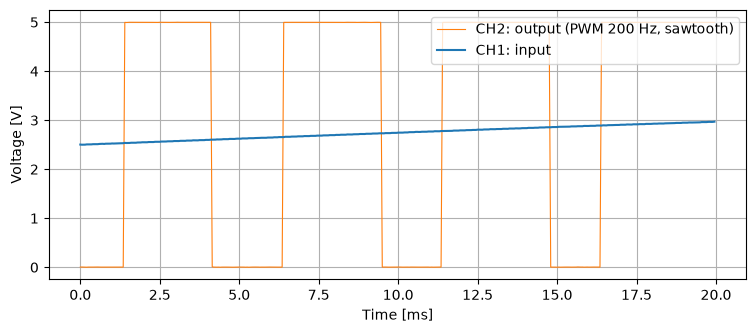

In [6]:
WAVE = "sawtooth"   # "triangle" or "sawtooth"

lab.fg.sine(5, 0.8)
lab.mimic.pwm(200, 1.0, WAVE)
time.sleep(0.2)
t, ch1, ch2 = lab.scope.capture(400)   # 20 ms
show(t, ch1, ch2, f"PWM 200 Hz, {WAVE}")

### 2. 搬送波の周波数を変える
<details><summary>ヒント</summary>

`FC` を 100 → 1000 Hz と変えてみましょう(実験 2 は 500)。平均の時間は搬送波の 1 周期です。

- 100 Hz:1 周期(10 ms)ごとにしか新しい値を表せないので、平均した正弦波が階段のようになり、入力より遅れます。
- 1000 Hz:なめらかになりますが、デューティ比のきざみ(0.5 %)が粗くなるうえ、測定器の取り込み(10 kHz)では 1 周期が 10 点しかないので、平均の線は少しがたつきます。

</details>

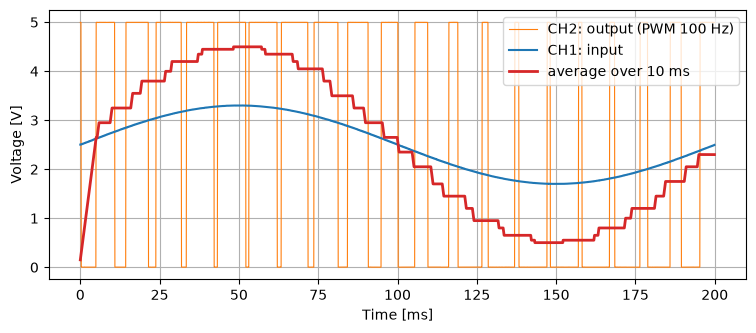

In [7]:
FC = 100   # carrier frequency [Hz]

lab.fg.sine(5, 0.8)
lab.mimic.pwm(FC, 1.0)
time.sleep(0.2)
t, ch1, ch2 = lab.scope.capture(2000, fs=10000)
n = max(1, round(10000 / FC))   # one carrier period
show(t, ch1, ch2, f"PWM {FC} Hz", (f"average over {1e3 / FC:g} ms", moving_average(ch2, n)))

### 3. V/F で周波数を振る
<details><summary>ヒント</summary>

入力に 5 Hz、振幅 0.4 V の三角波(2.1〜2.9 V)を入れて、`F0` を 500 → 0 → 1000 と変えてみましょう。感度は 1000 Hz/V です。

- 500:周波数は 100〜900 Hz のあいだを入力に合わせて変わります(6-2 の FM の方形波版)。
- 0:入力が 2.5 V より下のあいだ、出力は High のまま止まります。
- 1000:600〜1400 Hz。

</details>

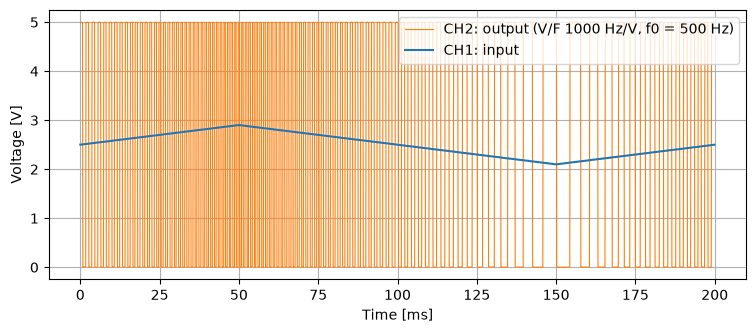

In [8]:
F0 = 500   # frequency at Vref [Hz]

lab.fg.triangle(5, 0.4)
lab.mimic.vf(1000, F0)
time.sleep(0.2)
t, ch1, ch2 = lab.scope.capture(2000, fs=10000)
show(t, ch1, ch2, f"V/F 1000 Hz/V, f0 = {F0} Hz")

## まとめ

- PWM は、入力を比較器で搬送波とくらべ、パルスの幅(デューティ比)で表す。平均すると入力に比例した電圧に戻る(D/A 変換)。
- 搬送波が三角波なら両側の縁が、のこぎり波なら片側の縁が動く。
- V/F 変換は、入力をパルスの周波数で表す。数えれば A/D 変換になる。
- Mimic では `pwm(fc, a, wave)`、`vf(k, f0)`(どちらもデジタル出力)。

最後に Mimic を素通し(バイパス)に戻して、接続を閉じます。

In [9]:
lab.mimic.bypass()
lab.fg.sine(100, 1.0)
lab.close()